# A/B Test Design & Sample Size Calculator

## Project Objective

The objective of this project is to calculate the required sample size for an A/B test, simulate statistical power, and demonstrate how repeated significance checking (peeking) increases false-positive rates.

We will analyze a checkout conversion experiment using a two-sided hypothesis test.

Additionally, we will verify the false-positive rate under the null hypothesis to ensure that the statistical significance level is properly controlled.

In [1]:
# ==========================================
# STEP 1: EXPERIMENT PARAMETERS
# ==========================================

p_control = 0.10
# Baseline conversion rate: 10%

p_variant = 0.12
# Expected conversion rate: 12%

alpha = 0.05
# Significance level: 5%

power = 0.80
# Statistical power: 80%

daily_traffic = 5000
# Eligible visitors per day

print("A/B TEST EXPERIMENT PARAMETERS")
print("-" * 40)

print(f"Control Conversion Rate: {p_control:.0%}")
print(f"Variant Conversion Rate: {p_variant:.0%}")
print(f"MDE: {(p_variant-p_control)*100:.1f} percentage points")
print(f"Significance Level: {alpha}")
print(f"Statistical Power: {power}")
print(f"Daily Traffic: {daily_traffic:,}")

A/B TEST EXPERIMENT PARAMETERS
----------------------------------------
Control Conversion Rate: 10%
Variant Conversion Rate: 12%
MDE: 2.0 percentage points
Significance Level: 0.05
Statistical Power: 0.8
Daily Traffic: 5,000


## Step 2: Sample Size Calculation

### Objective
Calculate the minimum number of participants required in each experiment group to detect a statistically significant difference in conversion rates.

### Methodology
We use a two-sided two-proportion sample size approximation based on:
- Baseline conversion rate
- Expected variant conversion rate
- Significance level (Alpha)
- Statistical power

We will compare three Minimum Detectable Effects (MDEs): 1, 2, and 3 percentage points.

A smaller detectable effect generally requires a larger sample size.

In [2]:
import numpy as np
import pandas as pd
from scipy.stats import norm

# Sample size calculation function

def n_per_group(p1, p2, alpha=0.05, power=0.80):

    z_alpha = norm.ppf(1 - alpha / 2)
    z_beta = norm.ppf(power)

    numerator = (
        (z_alpha + z_beta) ** 2
        * (p1 * (1 - p1) + p2 * (1 - p2))
    )

    denominator = (p2 - p1) ** 2

    n = np.ceil(numerator / denominator)

    return int(n)


# Calculate sample sizes for different MDEs

results = []

for mde in [0.01, 0.02, 0.03]:

    n = n_per_group(
        p1=p_control,
        p2=p_control + mde,
        alpha=alpha,
        power=power
    )

    total_sample = 2 * n
    duration = total_sample / daily_traffic

    results.append({
        "MDE": f"{mde * 100:.0f} percentage points",
        "Control Rate": f"{p_control:.0%}",
        "Variant Rate": f"{p_control + mde:.0%}",
        "Sample Per Group": n,
        "Total Sample": total_sample,
        "Duration (Days)": round(duration, 2)
    })

sample_size_df = pd.DataFrame(results)

sample_size_df

,MDE,Control Rate,Variant Rate,Sample Per Group,Total Sample,Duration (Days)
0,1 percentage points,10%,11%,14749,29498,5.90
1,2 percentage points,10%,12%,3839,7678,1.54
2,3 percentage points,10%,13%,1772,3544,0.71


### Key Findings

1. Detecting a 1 percentage-point improvement requires 14,749 participants per group.
2. Detecting a 2 percentage-point improvement requires 3,839 participants per group.
3. Detecting a 3 percentage-point improvement requires only 1,772 participants per group.

**Business Insight:**

Smaller improvements require substantially larger sample sizes. Therefore, experiment design involves balancing the business value of detecting small improvements against traffic availability and testing costs.

Although approximately 1.54 days are mathematically sufficient for our 2-point MDE, we will run the experiment for at least 7 days to capture weekday and weekend behavior.

In [3]:
# ==========================================
# GENERATE ONE SIMULATED EXPERIMENT
# ==========================================

rng = np.random.default_rng(42)

n = n_per_group(
    p_control,
    p_variant,
    alpha,
    power
)

# Generate control group
control_data = pd.DataFrame({
    "user_id": np.arange(1, n + 1),
    "group": "Control",
    "converted": rng.binomial(1, p_control, n)
})

# Generate variant group
variant_data = pd.DataFrame({
    "user_id": np.arange(n + 1, 2 * n + 1),
    "group": "Variant",
    "converted": rng.binomial(1, p_variant, n)
})

# Combine both groups
simulated_data = pd.concat(
    [control_data, variant_data],
    ignore_index=True
)

# Create data directory
import os

os.makedirs("data", exist_ok=True)

# Save CSV
simulated_data.to_csv(
    "data/simulated_ab_test_run.csv",
    index=False
)

print("Simulated dataset saved successfully!")
print("Total users:", len(simulated_data))
print("\nGroup distribution:")
print(simulated_data["group"].value_counts())

print("\nConversion summary:")
print(
    simulated_data.groupby("group")["converted"].agg(
        ["count", "sum", "mean"]
    )
)

Simulated dataset saved successfully!
Total users: 7678

Group distribution:
group
Control    3839
Variant    3839
Name: count, dtype: int64

Conversion summary:
         count  sum      mean
group                        
Control   3839  390  0.101589
Variant   3839  429  0.111748


### Simulation Methodology

We will run 10,000 independent simulations under two scenarios:

1. **Null Hypothesis:** Both groups have a 10% conversion rate. We expect approximately 5% statistically significant results (false-positive rate).
2. **Alternative Hypothesis:** Control has a 10% conversion rate and Variant has a 12% conversion rate. We expect approximately 80% statistically significant results (statistical power).

**Important:** These rates are long-run frequencies estimated across 10,000 independent experiments, not outcomes from a single experiment. Each simulation represents one independent A/B test.

## Step 3: Monte Carlo Simulation

### Objective
Verify the statistical power and false-positive rate of our A/B test using 10,000 independent simulations.

We will evaluate two scenarios:

- Null hypothesis: 10% vs 10% conversion.
- Alternative hypothesis: 10% vs 12% conversion.

The proportion of statistically significant results across simulations estimates the long-run false-positive rate and statistical power.

In [7]:
# ==========================================
# STEP 3: MONTE CARLO SIMULATION
# ==========================================

rng = np.random.default_rng(42)

n = n_per_group(
    p_control,
    p_variant,
    alpha,
    power
)
nsim = 10000

def run_sim(p_c, p_v, n, nsim=10000):

    xc = rng.binomial(n, p_c, nsim)
    xv = rng.binomial(n, p_v, nsim)

    pc = xc / n
    pv = xv / n

    pp = (xc + xv) / (2 * n)

    se = np.sqrt(pp * (1 - pp) * 2 / n)

    z = np.abs(pv - pc) / se

    p_values = 2 * norm.sf(z)

    return p_values


# Null hypothesis: 10% vs 10%
p_null = run_sim(0.10, 0.10, n, nsim)

# Alternative hypothesis: 10% vs 12%
p_alternative = run_sim(0.10, 0.12, n, nsim)


# Calculate long-run rates
false_positive_rate = np.mean(p_null < alpha)
statistical_power = np.mean(p_alternative < alpha)


print("MONTE CARLO SIMULATION RESULTS")
print("-" * 45)

print(f"Number of simulations: {nsim:,}")

print(
    f"Null false-positive rate: "
    f"{false_positive_rate:.2%} ({nsim:,} simulations)"
)

print(
    f"Alternative statistical power: "
    f"{statistical_power:.2%} ({nsim:,} simulations)"
)

MONTE CARLO SIMULATION RESULTS
---------------------------------------------
Number of simulations: 10,000
Null false-positive rate: 4.78% (10,000 simulations)
Alternative statistical power: 80.75% (10,000 simulations)


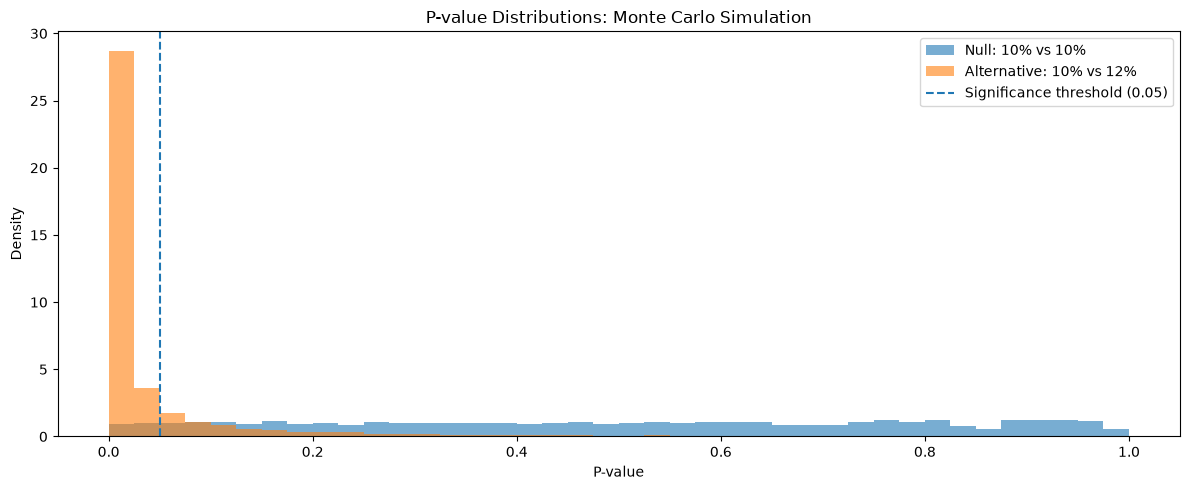

In [5]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.hist(
    p_null,
    bins=40,
    alpha=0.6,
    density=True,
    label="Null: 10% vs 10%"
)

plt.hist(
    p_alternative,
    bins=40,
    alpha=0.6,
    density=True,
    label="Alternative: 10% vs 12%"
)

plt.axvline(
    alpha,
    linestyle="--",
    label="Significance threshold (0.05)"
)

plt.xlabel("P-value")
plt.ylabel("Density")
plt.title("P-value Distributions: Monte Carlo Simulation")
plt.legend()
plt.tight_layout()
plt.show()

### Key Findings

- The null simulation estimates the false-positive rate when both groups have identical conversion rates.
- The alternative simulation estimates the statistical power when the variant improves conversion from 10% to 12%.
- Both results are long-run frequency estimates from 10,000 independent simulations, not outcomes from a single experiment.

The results help verify whether the sample size design achieves its intended statistical properties.

## Step 4: Peeking Simulation

### Objective
Demonstrate how repeatedly checking statistical significance before reaching the planned sample size inflates the false-positive rate.

### Methodology
- Both groups have an identical 10% conversion rate.
- The experiment is checked 8 times.
- Each check uses the accumulated observations.
- The experiment stops immediately when statistical significance is reached (p < 0.05).
- We repeat this process across 5,000 independent simulations.

The purpose is to compare the false-positive rate under repeated significance checking against the nominal 5% significance level.

In [6]:
# ==========================================
# STEP 4: PEEKING SIMULATION
# ==========================================

def peek_sim(p_c, p_v, n, checks=8, nsim=5000):

    sig = 0

    batch_sizes = np.full(checks, n // checks)
    batch_sizes[:n % checks] += 1

    for _ in range(nsim):

        xc = rng.binomial(batch_sizes, p_c).cumsum()
        xv = rng.binomial(batch_sizes, p_v).cumsum()

        stopped = False

        for k in range(checks):

            m = batch_sizes[:k+1].sum()

            pc = xc[k] / m
            pv = xv[k] / m

            pp = (xc[k] + xv[k]) / (2 * m)

            se = np.sqrt(pp * (1 - pp) * 2 / m)

            if se > 0:
                z = abs(pv - pc) / se

                p_value = 2 * norm.sf(z)

                if p_value < alpha:
                    stopped = True
                    break

        if stopped:
            sig += 1

    return sig / nsim


peeking_fpr = peek_sim(
    p_c=0.10,
    p_v=0.10,
    n=n,
    checks=8,
    nsim=5000
)

print("PEEKING SIMULATION RESULTS")
print("-" * 40)
print("Number of simulations: 5,000")
print("Number of significance checks: 8")
print(f"Peeking false-positive rate: {peeking_fpr:.2%} (5,000 simulations, 8 checks)")

PEEKING SIMULATION RESULTS
----------------------------------------
Number of simulations: 5,000
Number of significance checks: 8
Peeking false-positive rate: 17.68% (5,000 simulations, 8 checks)


### Key Finding: Peeking Inflates False Positives

Our simulation produced the following results:

- Standard fixed-sample testing false-positive rate: **4.78%** (10,000 simulations).
- Repeated peeking false-positive rate: **17.68%** (5,000 simulations; 8 checks).

In this simulation run, repeated unadjusted significance checking increased the false-positive rate to approximately 3.7 times the standard rate.

**Business implication:** Define the sample size and stopping rule before starting an A/B test. If interim monitoring is necessary, use a properly designed sequential-testing method or alpha-spending procedure instead of repeatedly applying the ordinary 0.05 threshold.